# Humans in the loop, and teams of agents

**Week 13 · Session 3**

Two sessions ago the graph ran start to finish on its own. Session 2 gave it memory and let
you rewind it. Today it learns the last two things a production system needs:

| | What it gives you | The LangGraph piece |
|---|---|---|
| **Pause** | stop mid-run, show a human something, carry on with their answer | `interrupt()` + `Command(resume=…)` |
| **Persist** | the pause survives a restart, a deploy, a weekend | a durable checkpointer (`SqliteSaver`) |
| **Split the work** | many steps at once, and specialists instead of one do-everything agent | `Send`, subgraphs, a supervisor |

**Today's project:** a Nimbus blog-writing team. An editor plans the post, **a human approves
the outline**, section writers work **in parallel** — each a subgraph with its own
fact-checker — and **nothing is published until a human signs it off**. Every idea from today
lands in that one graph.

There is an **appendix** at the end — a coding agent that writes code, runs hidden tests and
repairs itself. We may not reach it live; it runs standalone whenever you want it.

In [ ]:
%pip install -q "langchain==1.4.2" "langchain-openai==1.6.2" "langgraph==1.2.11" "langgraph-checkpoint-sqlite==3.1.1" python-dotenv

In [2]:
import os, json, re, ast, sys, time, sqlite3, operator, subprocess, tempfile, getpass
from pathlib import Path
from typing import Annotated, Literal, TypedDict

try:
    from dotenv import load_dotenv, find_dotenv
    load_dotenv(find_dotenv(usecwd=True) or Path.cwd().parent / ".env")
except ImportError:
    pass
if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass("OpenAI API key: ")

# Anaconda 'base' fix (same as Week 11). httpx2 2.12+ decompresses brotli with output_buffer_limit=... as a keyword.
# Anaconda's brotli 1.x exposes process() as a C function that rejects kwargs
# ("TypeError: process() takes no keyword arguments"). Wrap it so OpenAI
# Responses (which often arrive Content-Encoding: br) can be decoded.
try:
    import brotli as _brotli
    from httpx2._decoders import BrotliDecoder as _BrotliDecoder
    _probe = _brotli.Decompressor()
    try:
        _probe.process(b"", output_buffer_limit=1)
    except TypeError:
        _brotli_init = _BrotliDecoder.__init__
        def _brotli_init_compat(self, *args, **kwargs):
            _brotli_init(self, *args, **kwargs)
            _impl = self._decompress
            self._decompress = lambda data, output_buffer_limit=None, **_k: _impl(data)
        _BrotliDecoder.__init__ = _brotli_init_compat
except Exception:
    pass

from pydantic import BaseModel, Field
from IPython.display import Image, Markdown, display
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.types import interrupt, Command, Send
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.prebuilt import ToolNode
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain.messages import AIMessage, ToolMessage
from langchain.tools import tool
from langchain_openai import OpenAIEmbeddings
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_core.documents import Document

MODEL = "openai:gpt-4.1-mini"
llm = init_chat_model(MODEL, temperature=0)


def draw(graph, xray=False):
    """Show a compiled graph as a picture (needs internet), or as Mermaid text without it."""
    try:
        display(Image(graph.get_graph(xray=xray).draw_mermaid_png()))
    except Exception:
        print(graph.get_graph(xray=xray).draw_mermaid())


print("ready")

ready


---
# Part 1 — `interrupt()`: the pause button

Call `interrupt(payload)` inside a node and the graph **stops right there**. The payload goes
back to whoever called `invoke` — show it to a human however you like: a notebook cell, a
Slack message, a web form. When they answer, you call `invoke(Command(resume=answer))` and
`interrupt()` **returns** their answer inside the node, as if it had been waiting all along.

It needs a checkpointer — the graph has to be saved somewhere while it waits.

In [3]:
class Refund(TypedDict, total=False):
    order_id: str
    amount_inr: int
    decision: str
    log: Annotated[list[str], operator.add]


def propose(r: Refund) -> dict:
    return {"amount_inr": 4999, "log": ["proposed INR 4999"]}


def manager_approval(r: Refund) -> dict:
    answer = interrupt({"question": "Approve this refund?", "order": r["order_id"], "amount_inr": r["amount_inr"]})
    return {"decision": answer, "log": [f"manager said: {answer}"]}


def pay(r: Refund) -> dict:
    return {"log": ["PAID" if r["decision"] == "yes" else "not paid"]}


b = StateGraph(Refund)
b.add_node("propose", propose)
b.add_node("manager_approval", manager_approval)
b.add_node("pay", pay)
b.add_edge(START, "propose"); b.add_edge("propose", "manager_approval")
b.add_edge("manager_approval", "pay"); b.add_edge("pay", END)
refunds = b.compile(checkpointer=InMemorySaver())

cfg = {"configurable": {"thread_id": "refund-1"}}
result = refunds.invoke({"order_id": "N104455", "log": []}, cfg)

print("paused?     ", "__interrupt__" in result)
print("payload     ", result["__interrupt__"][0].value)
print("waiting at  ", refunds.get_state(cfg).next)
print("log so far  ", result["log"])

paused?      True
payload      {'question': 'Approve this refund?', 'order': 'N104455', 'amount_inr': 4999}
waiting at   ('manager_approval',)
log so far   ['proposed INR 4999']


The run is **parked** at `manager_approval`. Nothing is blocking — no thread is waiting, no
`input()` is hanging. The state is in the checkpointer. You could answer in five seconds or
five days.

In [4]:
result = refunds.invoke(Command(resume="yes"), cfg)
print(result["log"])

['proposed INR 4999', 'manager said: yes', 'PAID']


### The one surprise: the node runs again from the top

When you resume, LangGraph **re-runs the paused node from its first line**; this time
`interrupt()` returns the answer instead of pausing. So any code *before* the `interrupt()`
runs twice.

In [5]:
EMAILS_SENT = []


def careless_approval(r: Refund) -> dict:
    EMAILS_SENT.append(f"emailed manager about {r['order_id']}")      # side effect BEFORE interrupt
    answer = interrupt({"question": "Approve?", "amount_inr": r["amount_inr"]})
    return {"decision": answer}


b = StateGraph(Refund)
b.add_node("propose", propose); b.add_node("careless_approval", careless_approval)
b.add_edge(START, "propose"); b.add_edge("propose", "careless_approval"); b.add_edge("careless_approval", END)
careless = b.compile(checkpointer=InMemorySaver())

cfg = {"configurable": {"thread_id": "refund-2"}}
careless.invoke({"order_id": "N104455", "log": []}, cfg)
careless.invoke(Command(resume="yes"), cfg)
print(EMAILS_SENT)

['emailed manager about N104455', 'emailed manager about N104455']


Two emails for one approval. The rule: **put side effects after the `interrupt()`, or in a
node of their own.** Anything before it must be safe to repeat — reading state, formatting
the question.

---
# Part 2 — Approve, edit or reject a tool call

Last week `HumanInTheLoopMiddleware` let you approve, edit or reject a tool call. Here is
that feature built by hand, so you can see there's no magic in it — and change it.

Nimbus billing support: a safe tool (`lookup_order`) and a risky one (`issue_refund`). Only
the risky one goes through a human gate.

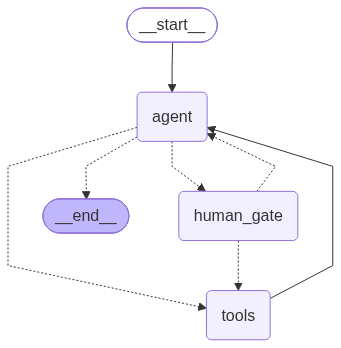

In [6]:
ORDERS = {
    "N104455": {"product": "Echo Bar", "paid_inr": 4999, "delivered": "3 days ago", "note": "charged twice"},
    "N104460": {"product": "Orbit", "paid_inr": 3999, "delivered": "2 days ago", "note": "customer reports a scratch"},
    "N104470": {"product": "Pulse X1", "paid_inr": 2499, "delivered": "20 days ago", "note": ""},
}
LEDGER = []          # the money that actually moved


@tool
def lookup_order(order_id: str) -> str:
    """Look up a Nimbus order: product, amount paid, when it was delivered, and any notes."""
    return json.dumps(ORDERS.get(order_id, "no such order"))


@tool
def issue_refund(order_id: str, amount_inr: int, reason: str) -> str:
    """Refund money to the customer. Moves real money."""
    LEDGER.append((order_id, amount_inr, reason))
    return f"Refunded INR {amount_inr} for {order_id}."


RISKY = {"issue_refund"}
support_tools = [lookup_order, issue_refund]
support_model = llm.bind_tools(support_tools, parallel_tool_calls=False)    # one call at a time: one decision at a time
SUPPORT_PROMPT = ("You are Nimbus billing support. Always look up the order first, then call issue_refund for what "
                  "the customer asks. Don't judge eligibility yourself and never say a refund is 'pending': a human "
                  "reviewer checks every issue_refund call before it runs, and you'll see their decision as the "
                  "tool's result. Then tell the customer the outcome in two sentences.")


def agent(state: MessagesState) -> dict:
    return {"messages": [support_model.invoke([{"role": "system", "content": SUPPORT_PROMPT}] + state["messages"])]}


def route(state: MessagesState) -> Literal["human_gate", "tools", "__end__"]:
    last = state["messages"][-1]
    if not last.tool_calls:
        return END
    if any(tc["name"] in RISKY for tc in last.tool_calls):
        return "human_gate"
    return "tools"


def human_gate(state: MessagesState) -> Command[Literal["tools", "agent"]]:
    last = state["messages"][-1]
    call = last.tool_calls[0]
    decision = interrupt({"tool": call["name"], "args": call["args"]})

    if decision["type"] == "approve":
        return Command(goto="tools")
    if decision["type"] == "edit":                      # same message id -> add_messages REPLACES the tool call
        edited = AIMessage(content=last.content, id=last.id, tool_calls=[{**call, "args": decision["args"]}])
        return Command(goto="tools", update={"messages": [edited]})
    # reject: answer the tool call ourselves, so the model hears why
    refusal = ToolMessage(f"A human reviewer REJECTED this refund: {decision['message']}", tool_call_id=call["id"])
    return Command(goto="agent", update={"messages": [refusal]})


def build_support(checkpointer):
    b = StateGraph(MessagesState)
    b.add_node("agent", agent)
    b.add_node("tools", ToolNode(support_tools))
    b.add_node("human_gate", human_gate)
    b.add_edge(START, "agent")
    b.add_conditional_edges("agent", route)
    b.add_edge("tools", "agent")
    return b.compile(checkpointer=checkpointer)


support = build_support(InMemorySaver())
draw(support)

Two new things in `human_gate`:

- It returns a **`Command(goto=…, update=…)`** — the node picks the next node *and* updates
  state in one go. The `Command[Literal["tools", "agent"]]` annotation tells LangGraph where it
  can go, so the picture is right.
- **Edit** works because of Session 1's reducer lesson: a message with the **same id**
  replaces the old one, so the tool call the tools node runs is the edited one.

A helper to run a turn and show either the pause or the answer:

In [7]:
def turn(graph, thread, message=None, resume=None):
    cfg = {"configurable": {"thread_id": thread}}
    if resume is not None and not graph.get_state(cfg).next:
        print("nothing is waiting for a human on thread", thread)
        return
    inp = Command(resume=resume) if resume is not None else {"messages": [{"role": "user", "content": message}]}
    out = graph.invoke(inp, cfg)
    if "__interrupt__" in out:
        print("⏸  waiting for a human:", out["__interrupt__"][0].value)
    else:
        print("💬", out["messages"][-1].content)


turn(support, "A", "I was charged twice for order N104455. Please refund the extra charge.")

⏸  waiting for a human: {'tool': 'issue_refund', 'args': {'order_id': 'N104455', 'amount_inr': 4999, 'reason': 'Charged twice for the same order'}}


In [8]:
turn(support, "A", resume={"type": "approve"})

💬 I have processed a refund of INR 4999 for the extra charge on your order N104455. Please allow some time for the refund to reflect in your account.


**Edit.** A scratch is worth a goodwill refund, not the full price. The reviewer changes the
amount before the tool runs.

In [9]:
turn(support, "B", "My Orbit (order N104460) arrived with a scratch. I want a full refund.")

⏸  waiting for a human: {'tool': 'issue_refund', 'args': {'order_id': 'N104460', 'amount_inr': 3999, 'reason': 'Product arrived with a scratch, customer requests full refund'}}


In [10]:
turn(support, "B", resume={"type": "edit",
                           "args": {"order_id": "N104460", "amount_inr": 500, "reason": "goodwill: cosmetic scratch"}})

💬 Your refund request for INR 500 due to the scratch on your Orbit has been processed for review. You will be notified once the human reviewer completes their check.


**Reject.** Delivered 20 days ago — outside the 7-day return window. The reviewer rejects with
a reason, and the model hears it as the tool's result.

In [11]:
turn(support, "C", "Refund order N104470 please, I don't like the colour.")

⏸  waiting for a human: {'tool': 'issue_refund', 'args': {'order_id': 'N104470', 'amount_inr': 2499, 'reason': 'Customer does not like the colour'}}


In [12]:
turn(support, "C", resume={"type": "reject",
                           "message": "Outside the 7-day return window. Offer a repair or replacement under the 12-month warranty only if it's faulty."})

💬 The refund request for order N104470 was reviewed and rejected because it is outside the 7-day return window. If the product is faulty, we can offer a repair or replacement under the 12-month warranty.


In [13]:
print("Money that actually moved:")
for row in LEDGER:
    print("  ", row)

Money that actually moved:
   ('N104455', 4999, 'Charged twice for the same order')
   ('N104460', 500, 'goodwill: cosmetic scratch')


Three requests, two refunds, and neither is the amount the model first asked for in case B.
The **ledger is the proof**: the risky tool only ran after a human said yes, with the
arguments the human chose.

---
# Part 3 — A pause that survives a restart

`InMemorySaver` lives in this Python process. Restart the kernel, and every paused
approval is gone. For anything real you need a checkpointer that writes to disk or a database.
`SqliteSaver` is the same interface, backed by a file.

In [14]:
DB = Path("support_checkpoints.db")
DB.unlink(missing_ok=True)                      # start clean each time the notebook runs

conn = sqlite3.connect(DB, check_same_thread=False)
support_db = build_support(SqliteSaver(conn))

turn(support_db, "D", "Order N104455 was charged twice, please refund the duplicate.")

⏸  waiting for a human: {'tool': 'issue_refund', 'args': {'order_id': 'N104455', 'amount_inr': 4999, 'reason': 'Duplicate charge refund requested by customer'}}


Now simulate a restart: close the database connection and throw the graph away. (In class,
you could really restart the kernel here — just rerun the setup cells and the next one.)

In [15]:
conn.close()
del support_db

# --- a brand-new process: new connection, new graph object, same file ---
conn = sqlite3.connect(DB, check_same_thread=False)
saver = SqliteSaver(conn)
support_db = build_support(saver)

# An approvals inbox: every thread that is parked at the human gate.
threads = {c.config["configurable"]["thread_id"] for c in saver.list(None)}
for t in sorted(threads):
    snap = support_db.get_state({"configurable": {"thread_id": t}})
    if snap.next:
        print(f"thread {t}: waiting at {snap.next} ->", snap.tasks[0].interrupts[0].value)

thread D: waiting at ('human_gate',) -> {'tool': 'issue_refund', 'args': {'order_id': 'N104455', 'amount_inr': 4999, 'reason': 'Duplicate charge refund requested by customer'}}


In [16]:
turn(support_db, "D", resume={"type": "approve"})

💬 The duplicate charge for order N104455 has been refunded for INR 4999. Please check your account for the refund confirmation.


The approval was given by a different graph object, over a different connection, to a run
that started "before the restart". That's what makes human-in-the-loop usable in production:
the human can take a day, and your server can redeploy in the meantime.

In production you'd use `langgraph-checkpoint-postgres` — the same interface again. The
`thread_id` becomes your ticket id, job id or conversation id.

---
Those three parts are the whole of human-in-the-loop: **pause**, **decide**, **resume** — and a
checkpointer that makes the pause survive anything.

The rest of today is the other half of a production system: **more than one worker.** One agent
with twenty tools gets confused, the same way one person doing every job does. LangGraph gives
you three ways to split the work, and we'll use all three in one project.

---
# Part 4 — `Send`: fan out, gather back

Some work is the same job done N times: grade each review, write each section, check each
file. Doing it in a `for` loop inside one node is slow and hides the work. **`Send`** lets a
conditional edge launch **one copy of a node per item**, all in the same step — so they run
in parallel — and a reducer gathers what they return.

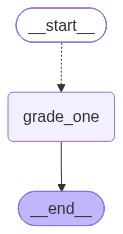

2/5  battery  Orbit got so hot on the charger I took it off at 3am. S
4/5  battery  Battery easily lasts 6 days, love the AMOLED screen.
2/5  app      App keeps logging me out, lost two runs. Fix it!
4/5  battery  After the April update it's been perfect. Charging is c
2/5  build    Strap broke in a week. Not what I expect for 4k.
4/5  sensors  Heart-rate tracking matches my chest strap. Impressed.

parallel with Send: 1.3s    one after another: 6.0s


In [17]:
REVIEWS = [
    "Orbit got so hot on the charger I took it off at 3am. Scary.",
    "Battery easily lasts 6 days, love the AMOLED screen.",
    "App keeps logging me out, lost two runs. Fix it!",
    "After the April update it's been perfect. Charging is cool now.",
    "Strap broke in a week. Not what I expect for 4k.",
    "Heart-rate tracking matches my chest strap. Impressed.",
]


class Grade(BaseModel):
    score: int = Field(ge=1, le=5)
    topic: Literal["heat", "battery", "app", "build", "sensors", "other"]


class Batch(TypedDict):
    reviews: list[str]
    grades: Annotated[list[dict], operator.add]      # each parallel copy APPENDS one grade


def fan_out(state: Batch) -> list[Send]:
    return [Send("grade_one", {"i": i, "text": t}) for i, t in enumerate(state["reviews"])]


def grade_one(item: dict) -> dict:                  # gets the Send payload, not the whole state
    g = llm.with_structured_output(Grade).invoke(f"Grade this smartwatch review.\n\n{item['text']}")
    return {"grades": [{"i": item["i"], **g.model_dump()}]}


b = StateGraph(Batch)
b.add_node("grade_one", grade_one)
b.add_conditional_edges(START, fan_out, ["grade_one"])
b.add_edge("grade_one", END)
grader = b.compile()
draw(grader)

t0 = time.time()
out = grader.invoke({"reviews": REVIEWS, "grades": []})
parallel_s = time.time() - t0

t0 = time.time()
for r in REVIEWS:
    llm.with_structured_output(Grade).invoke(f"Grade this smartwatch review.\n\n{r}")
sequential_s = time.time() - t0

for g in sorted(out["grades"], key=lambda g: g["i"]):
    print(f"{g['score']}/5  {g['topic']:<8} {REVIEWS[g['i']][:55]}")
print(f"\nparallel with Send: {parallel_s:.1f}s    one after another: {sequential_s:.1f}s")

Three things to notice:

- `fan_out` returns a **list of `Send(node, payload)`**. Each payload becomes that copy's input —
  the node doesn't see the whole state, just its item.
- The results come back **in whatever order they finish**. That's why each grade carries its
  `i`, and why we sort before printing.
- `grades` has a reducer. Without `operator.add`, six copies writing the same key in the same
  step would be an error — LangGraph can't guess how to combine them.

The number of copies is decided **at run time** by the data. That's the difference from
Session 1, where every branch was drawn in advance.

---
# Part 5 — Subgraphs: a team as one node

A **subgraph** is a compiled graph used inside another graph. Build a small, testable unit
once — here, a section writer with its own fact-checker — and drop it into bigger graphs.

This one takes a heading and a brief, researches the knowledge base, writes, and has a
**separate** checker compare the text against the sources. Unsupported claims go back to the
writer, at most twice.

The Nimbus knowledge base again — with the incident report and product notes the writers
will need later.

In [18]:
KB = {
    "returns-policy": "Returns within 7 days of delivery for a full refund. Defective products are replaced within "
                      "10 working days. Nimbus arranges FREE courier pickup; never ask customers to pay shipping.",
    "warranty-policy": "12-month warranty covering manufacturing defects. Liquid damage beyond the IP rating is not covered.",
    "orbit-product": "Orbit is Nimbus's smartwatch: 1.4-inch AMOLED screen, up to 7 days of battery, heart-rate and "
                     "SpO2 sensors, 5 ATM water resistance. Price INR 3999.",
    "smart-charging": "Smart charging learns your routine and holds the Orbit's battery at 80% overnight, finishing "
                      "the charge to 100% shortly before you usually wake up. It reduces long-term battery wear.",
    "orbit-incident-2026-03": "Incident report, March-April 2026: after firmware 2.3.0 (4 Mar 2026), some Orbit watches "
                              "became hot during smart charging. On 12 Mar Nimbus switched smart charging off remotely as "
                              "a precaution. The root cause was a timing bug in the charging controller. No injuries were "
                              "reported. Customers who returned an Orbit during the incident got a full refund even "
                              "outside the 7-day window.",
    "orbit-fw-2.3.1": "Orbit firmware 2.3.1 (10 Apr 2026) fixes the charging-controller timing bug behind the overheating, "
                      "the app logout bug and workout sync, and switches smart charging back on. It installs "
                      "automatically; users can also update from the app: Settings > Firmware.",
    "support-sla": "Email replies within 48 hours. Safety complaints must reach the product-safety team within 4 hours.",
    "echo-bar-manual": "Echo Bar is IPX5: splashes and rain, NOT submersion. Bluetooth range up to 10 m; walls reduce it.",
}
kb = InMemoryVectorStore.from_documents(
    [Document(page_content=t, metadata={"doc_id": d}) for d, t in KB.items()],
    OpenAIEmbeddings(model="text-embedding-3-small"))


def search(query: str, k: int = 3) -> str:
    return "\n".join(f"[{h.metadata['doc_id']}] {h.page_content}" for h in kb.similarity_search(query, k=k))


print(len(KB), "KB articles indexed")

8 KB articles indexed


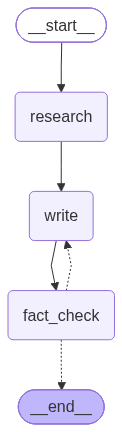

In [19]:
class SectionState(TypedDict, total=False):
    heading: str
    brief: str
    audience: str
    sources: str
    text: str
    unsupported: list[str]
    drafts: int


class FactCheck(BaseModel):
    unsupported: list[str] = Field(description="Claims in the text NOT supported by the sources. Empty if all supported.")


MAX_SECTION_DRAFTS = 2


def research(s: SectionState) -> dict:
    return {"sources": search(f"{s['heading']}. {s['brief']}")}


def write(s: SectionState) -> dict:
    fix = ""
    if s.get("unsupported"):
        fix = "\nA fact-checker found claims the sources don't support. Remove or correct them: " + "; ".join(s["unsupported"])
    text = llm.invoke(
        f"Write one section of a Nimbus blog post for {s['audience']}, 70-110 words, plain and warm. "
        f"Use ONLY facts from the sources; no numbers, dates or promises that aren't in them.{fix}\n\n"
        f"Heading: {s['heading']}\nBrief: {s['brief']}\n\nSources:\n{s['sources']}").content
    return {"text": text, "drafts": s.get("drafts", 0) + 1}


def fact_check(s: SectionState) -> dict:
    c = llm.with_structured_output(FactCheck).invoke(
        "You are a strict fact-checker. List every claim in the TEXT that the SOURCES do not support. "
        "General friendly phrasing is fine; facts, numbers, dates, causes and promises must be in the sources.\n\n"
        f"SOURCES:\n{s['sources']}\n\nTEXT:\n{s['text']}")
    return {"unsupported": c.unsupported}


def after_check(s: SectionState) -> Literal["write", "__end__"]:
    if s["unsupported"] and s["drafts"] < MAX_SECTION_DRAFTS:
        return "write"
    return END


sb = StateGraph(SectionState)
sb.add_node("research", research)
sb.add_node("write", write)
sb.add_node("fact_check", fact_check)
sb.add_edge(START, "research")
sb.add_edge("research", "write")
sb.add_edge("write", "fact_check")
sb.add_conditional_edges("fact_check", after_check)
section_writer = sb.compile()
draw(section_writer)

Test the unit on its own before using it anywhere — that's the point of a subgraph.

In [20]:
s = section_writer.invoke({"heading": "What is smart charging?",
                           "brief": "Explain the feature and why it's good for the battery.",
                           "audience": "Orbit owners"})
print(f"drafts: {s['drafts']}   unsupported claims left: {s['unsupported']}\n")
print(s["text"])

drafts: 1   unsupported claims left: []

### What is smart charging?

Smart charging is a feature that helps protect your Orbit’s battery by learning your daily routine. It keeps the battery at 80% overnight and finishes charging to 100% just before you usually wake up. This approach reduces long-term battery wear, helping your watch stay healthy for longer. After a recent update fixed a timing issue that caused overheating, smart charging is now safely back on and working smoothly. You can check your firmware version and update it easily through the app settings to enjoy this helpful feature.


Our writer is told to use only the sources, so it usually passes on the first draft. **Why
keep a checker at all?** Because a prompt is a request, not a guarantee. Here's what the same
checker says about a writer that *wasn't* told — the kind of copy a marketing prompt produces:

In [21]:
hype = llm.invoke("Write an upbeat 90-word section of a Nimbus blog post for Orbit owners titled "
                  "'How much better is the battery now?'. Make it exciting and specific.").content
print(hype, "\n")
verdict = fact_check({"sources": search("Orbit battery life, charging and firmware 2.3.1"), "text": hype})
for claim in verdict["unsupported"]:
    print("  ✗", claim)

**How much better is the battery now?**

Orbit owners, get ready to power up your adventures like never before! Our latest battery upgrade boosts your device’s life by an incredible 40%, meaning you can explore longer without hunting for a charger. Whether you’re tracking your gear on a weekend hike or navigating busy city streets, Orbit now stays energized for up to 72 hours straight. Plus, faster charging means less downtime—just 30 minutes to reach 80%! Say goodbye to battery anxiety and hello to unstoppable freedom with your upgraded Orbit. The future of tracking is brighter and longer-lasting! 



  ✗ The claim that the latest battery upgrade boosts the device’s life by an incredible 40%.
  ✗ The claim that Orbit now stays energized for up to 72 hours straight.
  ✗ The claim that faster charging means just 30 minutes to reach 80%.
  ✗ The overall claim of a battery upgrade improving battery life and charging speed.


Nothing in the knowledge base mentions a battery upgrade, a percentage or a charging speed —
the model made them up because "specific" was asked for and no sources were given. The
checker is cheap insurance: one extra call per section, and it's the step that stops a
confident, invented number reaching customers.

To use it inside another graph you have two options:

- **Same keys:** `parent.add_node("section", section_writer)` — the subgraph reads and writes
  the parent's state directly. Neat, but only when the schemas share keys.
- **Different keys:** call it from a node and translate — what we'll do in the project, because
  the blog's state and a section's state have nothing in common but the text.

---
# Part 6 — A supervisor and its specialists

Sometimes you **don't** know the order of work in advance. A **supervisor** is a model whose
only job is routing: after each specialist finishes, control comes back to the supervisor,
which decides who goes next — or that the job is done.

Three specialists, each a `create_agent` from last week with its **own** narrow tools:

In [22]:
TICKETS = {"orbit-heat": {"2026-W10": 18, "2026-W11": 64, "2026-W12": 71, "2026-W13": 29, "2026-W14": 17,
                          "2026-W15": 12, "2026-W16": 3, "2026-W17": 1}}


@tool
def search_kb(query: str) -> str:
    """Search Nimbus's internal knowledge base: policies, product docs, incident reports. Returns passages with [doc ids]."""
    return search(query)


@tool
def ticket_stats(tag: str) -> str:
    """Weekly support-ticket counts for a tag such as 'orbit-heat': counts per ISO week, the total and the peak week."""
    weeks = TICKETS.get(tag)
    if not weeks:
        return f"No tickets tagged {tag!r}. Known tags: {list(TICKETS)}"
    peak = max(weeks, key=weeks.get)
    return json.dumps({"weekly": weeks, "total": sum(weeks.values()), "peak_week": peak, "peak": weeks[peak]})


researcher = create_agent(llm, tools=[search_kb], system_prompt=(
    "You are a researcher. Use search_kb to find the facts the task needs. Reply with short bullet facts, "
    "each ending with its [doc id]. No opinions, nothing that isn't in a passage."))
analyst = create_agent(llm, tools=[ticket_stats], system_prompt=(
    "You are a data analyst. Use ticket_stats and report exact numbers from it only. Never estimate."))
writer = create_agent(llm, tools=[], system_prompt=(
    "You are a writer. Write what the task asks, using ONLY facts and numbers your teammates reported "
    "in this conversation. If something is missing, say so instead of inventing it."))
WORKERS = {"researcher": researcher, "analyst": analyst, "writer": writer}

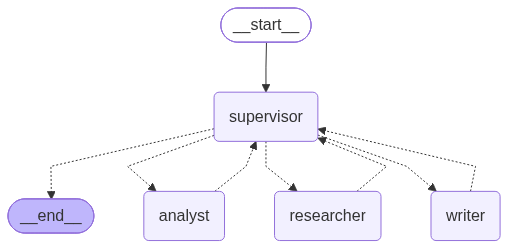

In [23]:
class Route(BaseModel):
    next: Literal["researcher", "analyst", "writer", "FINISH"]
    task: str = Field(description="One sentence: exactly what the chosen worker should do")


SUPERVISOR_PROMPT = (
    "You lead a team. researcher: facts from the knowledge base. analyst: support-ticket numbers. "
    "writer: writes the final text from the team's notes. Pick who works next and give them one clear task. "
    "Give each worker only work they are equipped for. Once the writer has delivered the final text, choose FINISH.")
MAX_HANDOFFS = 6


class Team(MessagesState):
    task: str
    handoffs: int
    trace: Annotated[list[str], operator.add]


def supervisor(state: Team) -> Command[Literal["researcher", "analyst", "writer", "__end__"]]:
    if state.get("handoffs", 0) >= MAX_HANDOFFS:                  # a budget, as always
        return Command(goto=END, update={"trace": ["supervisor: out of budget"]})
    r = llm.with_structured_output(Route).invoke([{"role": "system", "content": SUPERVISOR_PROMPT}] + state["messages"])
    if r.next == "FINISH":
        return Command(goto=END, update={"trace": ["supervisor → FINISH"]})
    return Command(goto=r.next, update={"task": r.task, "handoffs": state.get("handoffs", 0) + 1,
                                        "trace": [f"supervisor → {r.next}: {r.task}"]})


def make_worker(name: str):
    agent = WORKERS[name]

    def work(state: Team) -> Command[Literal["supervisor"]]:
        out = agent.invoke({"messages": state["messages"] + [
            {"role": "user", "content": f"Your task from the team lead: {state['task']}"}]})
        reply = out["messages"][-1].content
        return Command(goto="supervisor", update={"messages": [AIMessage(reply, name=name)]})
    return work


b = StateGraph(Team)
b.add_node("supervisor", supervisor)
for name in WORKERS:
    b.add_node(name, make_worker(name))
b.add_edge(START, "supervisor")
team = b.compile()
draw(team)

The picture is a star: every worker returns to the supervisor. No edges between workers —
the supervisor's `Command(goto=…)` is the only thing that decides the path.

In [24]:
ask = ("The CEO wants a five-line internal update on the Orbit overheating: what went wrong, "
       "how many support tickets it caused and when they peaked, and whether it's fixed.")
result = team.invoke({"messages": [{"role": "user", "content": ask}], "trace": []})

for step in result["trace"]:
    print(step)
print("\n" + result["messages"][-1].content)

supervisor → researcher: Find facts about the Orbit overheating issue, including what went wrong and whether it has been fixed.
supervisor → analyst: Find the number of support tickets caused by the Orbit overheating issue and identify when the ticket volume peaked.
supervisor → writer: Write a concise five-line internal update summarizing what went wrong with the Orbit overheating, the number and peak timing of support tickets, and whether the issue is fixed.
supervisor → FINISH

The Orbit overheating issue was caused by a timing bug in the charging controller introduced in firmware 2.3.0 released on 4 Mar 2026. This led to some watches becoming hot during smart charging, prompting Nimbus to disable smart charging remotely on 12 Mar 2026. The problem generated 215 support tickets, peaking at 71 tickets in the week of 2026-W12. A fix was deployed in firmware 2.3.1 on 10 Apr 2026, which also re-enabled smart charging. The update installs automatically or can be manually applied via the 

Read the trace. The supervisor sent the knowledge question to the researcher and the numbers
question to the analyst — each has only the tools for its job — then handed their notes to the
writer. You didn't draw that order; the model chose it from the request.

**Supervisor vs Week 11's handoffs.** With handoffs, the active agent passes control to the
next one directly (a relay). With a supervisor, control always comes back to the centre (a
hub). The hub costs an extra model call per step, but one place sees everything and one place
enforces the budget.

**Try it:** ask something that needs only the analyst ("which week had the most orbit-heat
tickets?") and watch the path shrink.

---
# Part 7 — Project: the Nimbus blog team

A blog post about the Orbit fix. This job's steps **are** known — plan, write, edit, sign
off — so it's a **workflow**, not a supervisor. Inside it, the parts that vary use today's
tools: `Send` for as many sections as the outline has, and the section-writer subgraph for
each one.

```
plan_outline → review_outline ⏸ → [write_section × N, in parallel] → assemble → edit → sign_off ⏸ → publish
                                                                              ↑__________|  (changes requested)
```

In [25]:
class SectionPlan(BaseModel):
    heading: str
    brief: str = Field(description="One sentence: what this section must cover")


class Outline(BaseModel):
    title: str
    sections: list[SectionPlan] = Field(min_length=3, max_length=5)


class Blog(TypedDict, total=False):
    topic: str
    audience: str
    outline: dict
    sections: Annotated[list[dict], operator.add]    # filled in parallel
    draft: str
    feedback: str
    revisions: int
    status: str
    log: Annotated[list[str], operator.add]


MAX_REVISIONS = 2

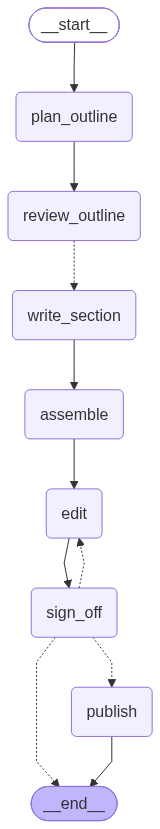

In [26]:
def plan_outline(b: Blog) -> dict:
    o = llm.with_structured_output(Outline).invoke(
        f"Plan a short Nimbus blog post for {b['audience']} on: {b['topic']}. 3-4 sections. "
        f"Only plan sections the knowledge base can support.\n\nWhat the knowledge base has:\n"
        + search(b["topic"], k=5))
    return {"outline": o.model_dump(), "log": ["plan_outline"]}


def review_outline(b: Blog) -> dict:
    d = interrupt({"step": "approve the outline", "outline": b["outline"]})
    if d["action"] == "edit":
        return {"outline": d["outline"], "log": ["outline edited by human"]}
    return {"log": ["outline approved by human"]}


def assign_sections(b: Blog) -> list[Send]:
    return [Send("write_section", {"i": i, "audience": b["audience"], **sec})
            for i, sec in enumerate(b["outline"]["sections"])]


def write_section(job: dict) -> dict:
    s = section_writer.invoke({"heading": job["heading"], "brief": job["brief"], "audience": job["audience"]})
    sources = sorted(set(line.split("]")[0][1:] for line in s["sources"].splitlines()))
    return {"sections": [{"i": job["i"], "heading": job["heading"], "text": s["text"], "drafts": s["drafts"],
                          "unsupported": s["unsupported"], "sources": sources}],
            "log": [f"write_section {job['i'] + 1}: {s['drafts']} draft(s), "
                    f"{len(s['unsupported'])} unsupported claim(s) left"]}


def assemble(b: Blog) -> dict:
    parts = [f"# {b['outline']['title']}"]
    for s in sorted(b["sections"], key=lambda s: s["i"]):
        parts.append(f"## {s['heading']}\n\n{s['text']}")
    return {"draft": "\n\n".join(parts), "log": ["assemble"]}


def edit(b: Blog) -> dict:
    notes = f"\nThe human reviewer asked for these changes - make them: {b['feedback']}" if b.get("feedback") else ""
    text = llm.invoke(
        "You are the editor. Smooth the transitions and make the tone consistent. Keep the markdown headings. "
        "Do NOT add facts, numbers or promises that aren't already in the draft; you may remove things."
        f"{notes}\n\nDRAFT:\n{b['draft']}").content
    return {"draft": text, "revisions": b.get("revisions", 0) + (1 if b.get("feedback") else 0),
            "feedback": "", "log": ["edit" + (" (with human notes)" if notes else "")]}


def sign_off(b: Blog) -> dict:
    d = interrupt({"step": "sign off to publish", "draft": b["draft"]})
    if d["action"] == "approve":
        return {"status": "approved", "log": ["signed off by human"]}
    return {"feedback": d["notes"], "log": ["changes requested by human"]}


def after_sign_off(b: Blog) -> Literal["publish", "edit", "__end__"]:
    if b.get("status") == "approved":
        return "publish"
    if b.get("revisions", 0) < MAX_REVISIONS:
        return "edit"
    return END                                     # too many rounds: a person takes over


def publish(b: Blog) -> dict:                      # the only side effect, in its own node, after every pause
    out = Path("blog")
    out.mkdir(exist_ok=True)
    path = out / "orbit-firmware-2-3-1.md"
    path.write_text(b["draft"])
    return {"status": f"published to {path}", "log": ["publish"]}


g = StateGraph(Blog)
for name, fn in [("plan_outline", plan_outline), ("review_outline", review_outline),
                 ("write_section", write_section), ("assemble", assemble), ("edit", edit),
                 ("sign_off", sign_off), ("publish", publish)]:
    g.add_node(name, fn)
g.add_edge(START, "plan_outline")
g.add_edge("plan_outline", "review_outline")
g.add_conditional_edges("review_outline", assign_sections, ["write_section"])
g.add_edge("write_section", "assemble")            # assemble waits for ALL the parallel copies
g.add_edge("assemble", "edit")
g.add_edge("edit", "sign_off")
g.add_conditional_edges("sign_off", after_sign_off)
g.add_edge("publish", END)
blog_team = g.compile(checkpointer=InMemorySaver())
draw(blog_team)

`write_section → assemble` is a normal edge, but `assemble` runs **once**, after **every**
parallel copy has finished. LangGraph runs in steps: all the `Send` copies are one step, and
the next step starts when they're all done.

## Run it

In [27]:
JOB = {"configurable": {"thread_id": f"blog-{int(time.time())}"}}


def go(inp):
    for update in blog_team.stream(inp, JOB, stream_mode="updates"):
        for node, change in update.items():
            if node == "__interrupt__":
                payload = change[0].value
                print(f"\n⏸  PAUSED: {payload['step']}")
                return payload
            for line in (change or {}).get("log", []):
                print("  ·", line)
    print("\n✅", blog_team.get_state(JOB).values.get("status"))


pause = go({"topic": "Orbit firmware 2.3.1: the overheating fix, what happened and how to update",
            "audience": "Orbit owners", "log": []})
print(json.dumps(pause["outline"], indent=2))

  · plan_outline

⏸  PAUSED: approve the outline
{
  "title": "Orbit firmware 2.3.1: the overheating fix, what happened and how to update",
  "sections": [
    {
      "heading": "Understanding the Overheating Issue in Orbit Watches",
      "brief": "Explain the overheating problem that occurred after firmware 2.3.0 and the actions taken by Nimbus."
    },
    {
      "heading": "What Firmware 2.3.1 Fixes",
      "brief": "Detail the fixes included in firmware 2.3.1, including the charging-controller timing bug, app logout bug, workout sync, and smart charging reactivation."
    },
    {
      "heading": "How to Update Your Orbit to Firmware 2.3.1",
      "brief": "Guide users on how the firmware installs automatically and how to manually update via the app settings."
    }
  ]
}


**You're the editor-in-chief.** You can approve the outline, or edit it — reorder, drop or
add sections. Here we approve it with one edit: we add a closing section with practical steps,
because customers will want to know what to *do*.

In [28]:
outline = pause["outline"]
outline["sections"].append({"heading": "What you need to do",
                            "brief": "How to check the watch has firmware 2.3.1 and update it from the app if not."})
pause = go(Command(resume={"action": "edit", "outline": outline}))

  · outline edited by human


  · write_section 1: 1 draft(s), 0 unsupported claim(s) left
  · write_section 3: 1 draft(s), 0 unsupported claim(s) left
  · write_section 2: 1 draft(s), 0 unsupported claim(s) left


  · write_section 4: 1 draft(s), 0 unsupported claim(s) left
  · assemble


  · edit

⏸  PAUSED: sign off to publish


Look at the `write_section` lines: one per section, arriving as a burst and not necessarily
in order — they ran in parallel and each reported when it finished. Each one went through its
own research → write → fact-check loop.

Now the draft is waiting for sign-off. Read it.

In [29]:
display(Markdown(pause["draft"]))

# Orbit firmware 2.3.1: the overheating fix, what happened and how to update

## Understanding the Overheating Issue in Orbit Watches

After the release of firmware 2.3.0, some Orbit watches experienced overheating during smart charging due to a timing bug in the charging controller. To keep users safe, Nimbus remotely switched off smart charging as a precaution. No injuries were reported, and customers who returned their watches during this time received full refunds, even beyond the usual return period. Nimbus addressed the issue with firmware 2.3.1, which fixed the bug and restored smart charging. The update installs automatically or can be manually applied through the app’s settings.

## What Firmware 2.3.1 Fixes

Firmware 2.3.1 resolves several important issues for Orbit owners. It fixes the charging-controller timing bug that caused some watches to overheat during smart charging. The update also addresses the app logout problem and improves workout syncing. With these fixes in place, smart charging is switched back on, helping protect your battery by learning your routine and managing charging overnight. The update installs automatically, but you can also update manually through the app under Settings > Firmware.

## How to Update Your Orbit to Firmware 2.3.1

Your Orbit watch will update to firmware 2.3.1 automatically, fixing the charging-controller timing bug and improving workout sync and app login. This update also switches smart charging back on, helping protect your battery by managing charging overnight based on your routine. If you prefer to update manually, open the Orbit app, go to Settings, then Firmware, and follow the prompts. Keeping your Orbit updated ensures it runs smoothly and safely.

## What You Need to Do

To ensure your Orbit watch is running smoothly, check that it has firmware version 2.3.1 installed. This update fixes issues like overheating during charging and workout syncing problems. You can see your current firmware in the app by going to Settings > Firmware. If your watch isn’t on 2.3.1 yet, you can update it there. While the update installs automatically, manually updating ensures you have the latest fixes and smart charging features working properly.

In [30]:
state = blog_team.get_state(JOB).values
for s in sorted(state["sections"], key=lambda s: s["i"]):
    print(f"section {s['i'] + 1}: {s['drafts']} draft(s), sources {s['sources']}, unsupported left: {s['unsupported']}")

section 1: 1 draft(s), sources ['orbit-fw-2.3.1', 'orbit-incident-2026-03', 'orbit-product'], unsupported left: []
section 2: 1 draft(s), sources ['orbit-fw-2.3.1', 'orbit-incident-2026-03', 'smart-charging'], unsupported left: []
section 3: 1 draft(s), sources ['orbit-fw-2.3.1', 'orbit-incident-2026-03', 'smart-charging'], unsupported left: []
section 4: 1 draft(s), sources ['orbit-fw-2.3.1', 'orbit-incident-2026-03', 'orbit-product'], unsupported left: []


The fact-check report is how you decide how carefully to read. A section that needed a
second draft is one where the writer reached beyond its sources the first time — worth a
closer look. A section with claims still flagged after its last draft must not go out as-is.

**Read the draft for repetition, too.** Parallel writers can't see each other. In the run
saved here, three different sections each explained how to update the watch. That's the price
of parallelism. Fix it upstream (the planner writes briefs that don't overlap) or downstream
(tell the editor to cut repeats) — exercise 7.

**Request a change**, the way an editor would:

In [31]:
pause = go(Command(resume={"action": "revise",
                           "notes": "Open with the apology and the fact that it's fixed, before the details. "
                                    "Keep the whole post under 400 words."}))
display(Markdown(pause["draft"]))

  · changes requested by human


  · edit (with human notes)

⏸  PAUSED: sign off to publish


# Orbit firmware 2.3.1: the overheating fix, what happened and how to update

We apologize for the overheating issue some Orbit watches experienced after the 2.3.0 firmware release. This problem has now been fully resolved with firmware 2.3.1, which restores smart charging safely.  

## Understanding the Overheating Issue in Orbit Watches

The overheating was caused by a timing bug in the charging controller during smart charging. To protect users, Nimbus remotely disabled smart charging as a precaution. No injuries were reported, and customers who returned their watches during this period received full refunds, even beyond the usual return window. Firmware 2.3.1 fixes this bug and safely re-enables smart charging.

## What Firmware 2.3.1 Fixes

Firmware 2.3.1 addresses the charging-controller timing bug that led to overheating. It also resolves the app logout issue and improves workout syncing. With these fixes, smart charging is switched back on, allowing your watch to manage charging overnight based on your routine and help protect your battery.

## How to Update Your Orbit to Firmware 2.3.1

The update installs automatically, but you can also update manually through the Orbit app by going to Settings > Firmware and following the prompts. Keeping your watch updated ensures it runs smoothly and safely with all the latest fixes and features.

## What You Need to Do

Check your Orbit’s firmware version in the app under Settings > Firmware. If it’s not yet on 2.3.1, update it there to benefit from the overheating fix, improved workout syncing, and restored smart charging. While the update installs automatically, manually updating guarantees you have the latest improvements working properly.

In [32]:
pause = go(Command(resume={"action": "approve"}))
print(Path("blog/orbit-firmware-2-3-1.md").read_text()[:400], "...")

  · signed off by human
  · publish

✅ published to blog/orbit-firmware-2-3-1.md
# Orbit firmware 2.3.1: the overheating fix, what happened and how to update

We apologize for the overheating issue some Orbit watches experienced after the 2.3.0 firmware release. This problem has now been fully resolved with firmware 2.3.1, which restores smart charging safely.  

## Understanding the Overheating Issue in Orbit Watches

The overheating was caused by a timing bug in the charging ...


## The whole journey

In [33]:
final = blog_team.get_state(JOB).values
print(" → ".join(final["log"]))
print("\nwords:", len(final["draft"].split()), "  status:", final["status"])

plan_outline → outline edited by human → write_section 1: 1 draft(s), 0 unsupported claim(s) left → write_section 2: 1 draft(s), 0 unsupported claim(s) left → write_section 3: 1 draft(s), 0 unsupported claim(s) left → write_section 4: 1 draft(s), 0 unsupported claim(s) left → assemble → edit → changes requested by human → edit (with human notes) → signed off by human → publish

words: 266   status: published to blog/orbit-firmware-2-3-1.md


## Trust, but verify

The human approved an outline with a section they added themselves. Is it still in what was
published?

In [34]:
approved = [s["heading"] for s in final["outline"]["sections"]]
published = [line[3:].strip() for line in final["draft"].splitlines() if line.startswith("## ")]
for h in approved:
    kept = any(h.lower() == p.lower() for p in published)
    print("✓ kept     " if kept else "✗ MISSING  ", h)

✓ kept      Understanding the Overheating Issue in Orbit Watches
✓ kept      What Firmware 2.3.1 Fixes
✓ kept      How to Update Your Orbit to Firmware 2.3.1
✓ kept      What you need to do


This time every approved heading survived — four ticks, nothing missing. Good. **So why keep
the check?**

Because on an earlier run of this exact notebook it printed:

```
✗ MISSING   What you need to do      ← the section the human added
```

The editor — asked to keep the post under 400 words, and allowed by its prompt to "remove
things" — silently deleted the section the human had added at the outline stage. The scripted
sign-off approved it anyway, because in this notebook the approval is a cell, not a person
reading carefully.

Same code, same prompt, different day. **That is exactly the kind of bug you cannot catch by
looking at one run.**

Two lessons:

- **Don't give a step more power than it needs.** "You may remove things" let the editor
  undo a human decision. Tighten the prompt: keep every section; shorten inside them.
- **Check human decisions in code.** "Every approved heading is still there" is a
  deterministic rule. It belongs in a node before `sign_off`, not in the hope that the
  reviewer notices (exercise 8).

---
# Appendix — a code agent that repairs itself

*Optional: we may not reach this live. It runs on its own, and it is the best single example of
a bounded repair loop.*

**The job.** A developer ticket comes in. The agent must plan, have a human approve the plan,
write the code, check it statically, run **hidden tests it has never seen**, debug its own
failures up to a budget, and ask a human for a hint when it is stuck.

In [35]:
TICKET = """Ticket NIM-482 - add delivery_window(city, ordered_at, express=False) -> (earliest, latest)

Return ISO dates ('YYYY-MM-DD'). ordered_at looks like '2026-09-14 10:00'.
Shipping policy: metros (Mumbai, Delhi, Bengaluru, Chennai, Kolkata, Hyderabad) 1-3 days,
north-east (Guwahati, Shillong, Imphal, Agartala) 7-10 days, everywhere else 3-5 days.
Business days only - we don't deliver on Sundays or warehouse holidays (2026-10-02, 2026-11-09).
Orders after 6 pm go out the next day. Express halves the time; metros only.
Standard library only."""

Questions a careful engineer would ask: *is 18:00 "after 6 pm"? Does "1 day" mean tomorrow?
Halving 3 days gives 1.5 — round up or down? What does "metros only" do for Pune — error, or
ignore it? What if the next day is a holiday too?* The ticket doesn't say. **The tests do.**

## The hidden tests

QA's acceptance tests. They're written to a file next to the agent's code and run in a
separate process. The agent only ever sees **which calls failed** — the way you see CI output.

In [36]:
HIDDEN_TESTS = r'''
import json, sys
sys.path.insert(0, ".")
from solution import delivery_window

CASES = [   # (args, kwargs, expected)
    (("Mumbai", "2026-09-14 10:00"), {}, ("2026-09-15", "2026-09-17")),
    ((" pune ", "2026-09-14 10:00"), {}, ("2026-09-17", "2026-09-19")),
    (("Guwahati", "2026-09-14 10:00"), {}, ("2026-09-22", "2026-09-25")),
    (("Delhi", "2026-09-18 11:00"), {}, ("2026-09-19", "2026-09-22")),
    (("Chennai", "2026-09-19 19:30"), {}, ("2026-09-22", "2026-09-24")),
    (("Kolkata", "2026-09-16 18:00"), {}, ("2026-09-18", "2026-09-21")),
    (("Kolkata", "2026-09-16 17:59"), {}, ("2026-09-17", "2026-09-19")),
    (("Jaipur", "2026-09-20 09:00"), {}, ("2026-09-24", "2026-09-26")),
    (("HYDERABAD", "2026-09-17 12:00"), {"express": True}, ("2026-09-18", "2026-09-19")),
    (("Pune", "2026-09-17 12:00"), {"express": True}, "ValueError"),
    (("Shillong", "2026-09-26 20:00"), {}, ("2026-10-07", "2026-10-10")),
    (("Mumbai", "2026-10-01 19:00"), {}, ("2026-10-05", "2026-10-07")),
    (("Bengaluru", "2026-11-07 18:30"), {}, ("2026-11-11", "2026-11-13")),
]

failures = []
for args, kwargs, want in CASES:
    call = "delivery_window(" + ", ".join([repr(a) for a in args] + [f"{k}={v!r}" for k, v in kwargs.items()]) + ")"
    try:
        got = delivery_window(*args, **kwargs)
        got = tuple(got) if isinstance(got, (list, tuple)) else got
    except ValueError:
        got = "ValueError"
    except Exception as e:
        got = f"{type(e).__name__}: {e}"
    if got != want:
        failures.append(f"{call}: expected {want!r}, got {got!r}")
print(json.dumps({"total": len(CASES), "failures": failures}))
'''
N_TESTS = 13                       # len(CASES) in the hidden file
print(N_TESTS, "hidden tests")

13 hidden tests


## Running model-written code, carefully

Executing code a model wrote is the riskiest thing in this course. Three layers here:

- **A human approves the plan** before any code exists.
- **A static check** parses the code and refuses imports outside an allow-list and calls like
  `open`, `exec` or `eval` — before anything runs.
- **A separate process** in a throwaway folder, isolated mode (`python -I`), killed after 10 seconds.

That is **not a real sandbox** — a determined program could still do harm. In production
you'd run it in a container or a hosted sandbox with no network and no secrets. The shape of
the graph stays the same; only `run_hidden_tests` changes.

In [37]:
ALLOWED_IMPORTS = {"datetime", "math", "re", "calendar"}
FORBIDDEN_CALLS = {"open", "exec", "eval", "compile", "__import__", "input"}


def static_check(code: str) -> str:
    """Return '' if the code looks safe to run, else the reason it isn't."""
    try:
        tree = ast.parse(code)
    except SyntaxError as e:
        return f"SyntaxError: {e}"
    for node in ast.walk(tree):
        if isinstance(node, (ast.Import, ast.ImportFrom)):
            mods = [a.name for a in node.names] if isinstance(node, ast.Import) else [node.module or ""]
            bad = [m for m in mods if m.split(".")[0] not in ALLOWED_IMPORTS]
            if bad:
                return f"import not allowed: {bad}. Allowed: {sorted(ALLOWED_IMPORTS)}"
        if isinstance(node, ast.Call) and getattr(node.func, "id", "") in FORBIDDEN_CALLS:
            return f"call not allowed: {node.func.id}()"
    if "def delivery_window" not in code:
        return "no function named delivery_window"
    return ""


def run_hidden_tests(code: str) -> dict:
    with tempfile.TemporaryDirectory() as folder:
        Path(folder, "solution.py").write_text(code)
        Path(folder, "test_hidden.py").write_text(HIDDEN_TESTS)
        try:
            p = subprocess.run([sys.executable, "-I", "test_hidden.py"], cwd=folder,
                               capture_output=True, text=True, timeout=10)
        except subprocess.TimeoutExpired:
            return {"total": N_TESTS, "failures": ["timed out after 10 seconds - an infinite loop?"]}
    if p.returncode != 0:
        return {"total": N_TESTS, "failures": [p.stderr.strip().splitlines()[-1]]}
    return json.loads(p.stdout)


print(static_check("import os\nos.remove('x')"))
print(static_check("def delivery_window(c, o, express=False):\n    return ('', '')"))
print(run_hidden_tests("def delivery_window(c, o, express=False):\n    return ('2026-09-15', '2026-09-17')")["failures"][:2])

import not allowed: ['os']. Allowed: ['calendar', 'datetime', 'math', 're']

["delivery_window(' pune ', '2026-09-14 10:00'): expected ('2026-09-17', '2026-09-19'), got ('2026-09-15', '2026-09-17')", "delivery_window('Guwahati', '2026-09-14 10:00'): expected ('2026-09-22', '2026-09-25'), got ('2026-09-15', '2026-09-17')"]


The last line is a "solution" that always returns the same dates: one test passes by luck,
the rest fail with a message a developer (or a model) can act on.

## The state

In [38]:
class Job(TypedDict, total=False):
    ticket: str
    plan: str
    plan_feedback: str       # from the human plan review
    code: str
    problem: str             # static-check error or failing tests: what the debugger sees
    report: dict
    attempts: int            # test runs so far
    max_attempts: int        # raised when a human gives a hint
    hints: list[str]
    status: str
    log: Annotated[list[str], operator.add]


MAX_ATTEMPTS = 3
MAX_HINTS = 2

## The nodes

In [39]:
def code_of(text: str) -> str:
    m = re.search(r"```(?:python)?\n(.*?)```", text, re.S)
    return (m.group(1) if m else text).strip() + "\n"


def make_plan(j: Job) -> dict:
    fb = f"\n\nThe reviewer sent your last plan back with this feedback: {j['plan_feedback']}" if j.get("plan_feedback") else ""
    plan = llm.invoke("You are a senior engineer. Before writing any code, list the rules and edge cases you "
                      f"will handle, as 5-8 short bullets. No code.{fb}\n\nTicket:\n{j['ticket']}").content
    return {"plan": plan, "log": ["make_plan"]}


def review_plan(j: Job) -> dict:
    d = interrupt({"step": "review the plan", "plan": j["plan"]})
    if d["action"] == "approve":
        return {"plan_feedback": "", "log": ["plan approved by human"]}
    return {"plan_feedback": d["feedback"], "log": ["plan sent back by human"]}


def write_code(j: Job) -> dict:
    text = llm.invoke("Implement this ticket in Python, following the approved plan. "
                      "Reply with a single ```python block.\n\n"
                      f"Ticket:\n{j['ticket']}\n\nApproved plan:\n{j['plan']}").content
    return {"code": code_of(text), "log": ["write_code"]}


def check_code(j: Job) -> dict:
    problem = static_check(j["code"])
    return {"problem": problem, "log": ["check_code: " + (problem or "ok")]}


def run_tests(j: Job) -> dict:
    report = run_hidden_tests(j["code"])
    n = j.get("attempts", 0) + 1
    passed = report["total"] - len(report["failures"])
    return {"report": report, "attempts": n, "problem": "\n".join(report["failures"]),
            "log": [f"run_tests #{n}: {passed}/{report['total']} passed"]}


def debug(j: Job) -> dict:
    hints = "".join(f"\nA human engineer says: {h}" for h in j.get("hints", []))
    text = llm.invoke("Your code has problems. Fix them. The failing tests are the source of truth where the "
                      "ticket is vague. Reply with the complete corrected module in a single ```python block."
                      f"{hints}\n\nTicket:\n{j['ticket']}\n\nYour code:\n```python\n{j['code']}```\n\n"
                      f"Problems:\n{j['problem']}").content
    return {"code": code_of(text), "log": ["debug"]}


def ask_human(j: Job) -> dict:
    d = interrupt({"step": "stuck - tests still failing", "attempts": j["attempts"],
                   "failures": j["report"]["failures"]})
    if d["action"] == "give_up":
        return {"status": "given up by human", "log": ["human: give up"]}
    return {"hints": j.get("hints", []) + [d["hint"]], "max_attempts": j["attempts"] + 2,
            "log": ["human: hint"]}


def ship(j: Job) -> dict:
    return {"status": f"all {j['report']['total']} tests pass after {j['attempts']} run(s)", "log": ["ship"]}


def give_up(j: Job) -> dict:
    return {"status": "stopped: out of attempts and hints", "log": ["give_up"]}

## The routing

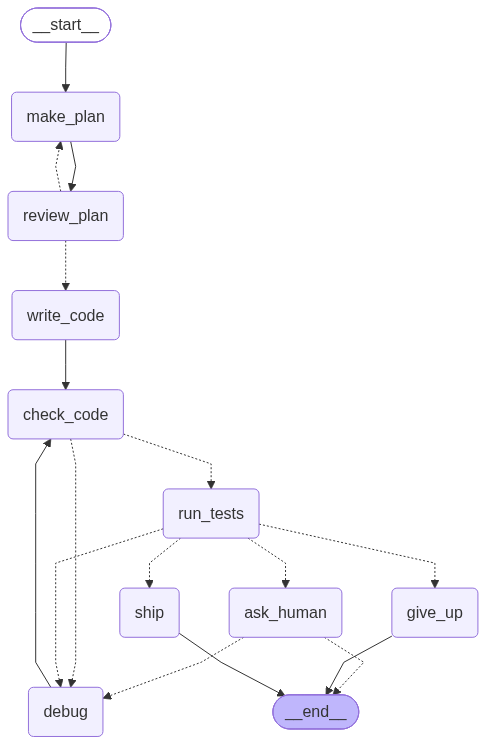

In [40]:
def after_plan_review(j: Job) -> Literal["write_code", "make_plan"]:
    return "make_plan" if j.get("plan_feedback") else "write_code"


def after_check(j: Job) -> Literal["run_tests", "debug"]:
    return "debug" if j["problem"] else "run_tests"          # unsafe or broken code never runs


def after_tests(j: Job) -> Literal["ship", "debug", "ask_human", "give_up"]:
    if not j["report"]["failures"]:
        return "ship"
    if j["attempts"] < j["max_attempts"]:
        return "debug"                                        # the repair loop
    if len(j.get("hints", [])) < MAX_HINTS:
        return "ask_human"                                    # budget spent: escalate
    return "give_up"                                          # even the human budget is spent


def after_human(j: Job) -> Literal["debug", "__end__"]:
    return END if j.get("status") else "debug"


b = StateGraph(Job)
for name, fn in [("make_plan", make_plan), ("review_plan", review_plan), ("write_code", write_code),
                 ("check_code", check_code), ("run_tests", run_tests), ("debug", debug),
                 ("ask_human", ask_human), ("ship", ship), ("give_up", give_up)]:
    b.add_node(name, fn)
b.add_edge(START, "make_plan")
b.add_edge("make_plan", "review_plan")
b.add_conditional_edges("review_plan", after_plan_review)
b.add_edge("write_code", "check_code")
b.add_edge("debug", "check_code")
b.add_conditional_edges("check_code", after_check)
b.add_conditional_edges("run_tests", after_tests)
b.add_conditional_edges("ask_human", after_human)
b.add_edge("ship", END)
b.add_edge("give_up", END)

code_conn = sqlite3.connect("code_agent.db", check_same_thread=False)
coder = b.compile(checkpointer=SqliteSaver(code_conn))
draw(coder)

Two loops, both bounded: `debug → check_code → run_tests → debug` (by `max_attempts`) and
`ask_human → debug` (by `MAX_HINTS`). Two pauses: the plan review and the cry for help.
Everything is checkpointed to `code_agent.db`, so you can stop at either pause and come back
tomorrow.

## Run it

`go()` streams node updates as they happen and stops at a pause.

In [41]:
JOB = {"configurable": {"thread_id": f"NIM-482-{int(time.time())}"}}   # a fresh job each run


def go(inp):
    for update in coder.stream(inp, JOB, stream_mode="updates"):
        for node, change in update.items():
            if node == "__interrupt__":
                payload = change[0].value
                print(f"\n⏸  PAUSED: {payload['step']}")
                return payload
            for line in (change or {}).get("log", []):
                print("  ·", line)
    state = coder.get_state(JOB).values
    print("\n✅", state.get("status"))
    return None


pause = go({"ticket": TICKET, "max_attempts": MAX_ATTEMPTS, "hints": [], "log": []})
display(Markdown(pause["plan"]))

  · make_plan

⏸  PAUSED: review the plan


- Validate city input and categorize into metro, north-east, or other regions; handle unknown cities gracefully.  
- Parse `ordered_at` datetime and adjust for orders placed after 6 pm by shifting the start date to the next business day.  
- Calculate delivery windows in business days only, skipping Sundays and specified warehouse holidays.  
- For express deliveries (only allowed for metros), halve the delivery time range, rounding appropriately.  
- Ensure the returned dates are in ISO format ('YYYY-MM-DD').  
- Handle edge cases where delivery window spans weekends and multiple holidays.  
- If express=True for non-metro cities, fallback to standard delivery times or raise an error.  
- Consider time zone consistency if relevant (assume input times are local or UTC as per spec).

**You're the reviewer.** Read the plan. Does it answer the questions the ticket left open —
18:00, rounding, Pune with express, a holiday after a Sunday? Approve it as-is to see the
repair loop work, or send it back with feedback to see the plan loop fire.

In [42]:
pause = go(Command(resume={"action": "approve"}))

  · plan approved by human


  · write_code
  · check_code: ok
  · run_tests #1: 11/13 passed


  · debug
  · check_code: ok
  · run_tests #2: 10/13 passed


  · debug
  · check_code: ok
  · run_tests #3: 12/13 passed

⏸  PAUSED: stuck - tests still failing


If it stopped to ask for help, **read the failing tests** and write a hint the way you'd
nudge a junior colleague: point at the rule, don't paste the answer. The hint below is
deliberately generic, because every run gets stuck somewhere different. In class, replace it
with one that names the rule you can see is being missed.

In [43]:
if pause and pause["step"].startswith("stuck"):
    for f in pause["failures"]:
        print("  ✗", f)
    HINT = ("Take each failing call literally: the expected value IS the policy. For each one, work out which "
            "rule of the ticket it pins down - a time cutoff, a rounding rule, an error case - and change only that.")
    pause = go(Command(resume={"action": "hint", "hint": HINT}))
else:
    print("No human needed on this run.")

  ✗ delivery_window('Pune', '2026-09-17 12:00', express=True): expected 'ValueError', got ('2026-09-21', '2026-09-23')
  · human: hint


  · debug
  · check_code: ok
  · run_tests #4: 13/13 passed
  · ship

✅ all 13 tests pass after 4 run(s)


## What happened

The whole trajectory, and the code that shipped:

In [44]:
final = coder.get_state(JOB).values
print("status  :", final["status"])
print("journey :", " → ".join(l.split(":")[0] for l in final["log"]))
print("hints   :", final.get("hints"))
display(Markdown(f"```python\n{final['code']}```"))

status  : all 13 tests pass after 4 run(s)
journey : make_plan → plan approved by human → write_code → check_code → run_tests #1 → debug → check_code → run_tests #2 → debug → check_code → run_tests #3 → human → debug → check_code → run_tests #4 → ship
hints   : ['Take each failing call literally: the expected value IS the policy. For each one, work out which rule of the ticket it pins down - a time cutoff, a rounding rule, an error case - and change only that.']


```python
from datetime import datetime, timedelta
from math import floor, ceil

def delivery_window(city, ordered_at, express=False):
    # Define city categories
    metros = {"mumbai", "delhi", "bengaluru", "chennai", "kolkata", "hyderabad"}
    north_east = {"guwahati", "shillong", "imphal", "agartala"}
    warehouse_holidays = {datetime(2026, 10, 2).date(), datetime(2026, 11, 9).date()}
    
    city_clean = city.strip().lower()
    # Categorize city
    if city_clean in metros:
        region = "metro"
    elif city_clean in north_east:
        region = "north_east"
    else:
        # Everywhere else
        region = "other"
    
    # Parse ordered_at datetime
    try:
        dt_ordered = datetime.strptime(ordered_at, "%Y-%m-%d %H:%M")
    except ValueError:
        raise ValueError("ordered_at must be in 'YYYY-MM-DD HH:MM' format")
    
    # Helper function to check if a date is a business day
    def is_business_day(date):
        # Sunday is 6 in weekday() (Monday=0)
        if date.weekday() == 6:
            return False
        if date in warehouse_holidays:
            return False
        return True
    
    # Helper function to get next business day on or after given date
    def next_business_day(date):
        d = date
        while not is_business_day(d):
            d += timedelta(days=1)
        return d
    
    # Adjust start date if order placed after 6 pm
    cutoff_hour = 18
    order_date = dt_ordered.date()
    order_time = dt_ordered.time()
    if order_time.hour >= cutoff_hour:
        # Start counting from next business day after order_date
        start_date = next_business_day(order_date + timedelta(days=1))
    else:
        # If order_date is not business day, start from next business day
        start_date = next_business_day(order_date)
    
    # Determine delivery days range
    if region == "metro":
        min_days, max_days = 1, 3
    elif region == "north_east":
        min_days, max_days = 7, 10
    else:
        min_days, max_days = 3, 5
    
    # Handle express
    if express:
        # According to failing test, express=True for non-metro cities must raise ValueError
        if region != "metro":
            raise ValueError("Express delivery is only available for metro cities")
        # Halve delivery time range, rounding appropriately
        # For min_days: round down (floor)
        # For max_days: round up (ceil)
        min_days = max(1, floor(min_days / 2))
        max_days = max(min_days, ceil(max_days / 2))
    
    # Helper to add business days to a start date
    def add_business_days(start, days):
        current = start
        added = 0
        while added < days:
            current += timedelta(days=1)
            if is_business_day(current):
                added += 1
        return current
    
    earliest = add_business_days(start_date, min_days)
    latest = add_business_days(start_date, max_days)
    
    return (earliest.isoformat(), latest.isoformat())
```

In [45]:
# Did it really pass? Run the hidden tests one more time, independently of the graph.
print(run_hidden_tests(final["code"]))

{'total': 13, 'failures': []}


Look at the journey. The first version almost certainly didn't pass: the ticket was vague,
and the model guessed. The failing tests told it which guesses were wrong, and the loop fixed
them one run at a time. When the tests alone weren't enough, a human spent ten seconds on a
hint instead of an hour on the code.

Runs differ: sometimes the first repair fixes everything, sometimes it needs the human.
The graph handles every case, because every case is an edge.

### Passing tests is not the same as good code

Now **read the code that shipped**. In the run saved in this notebook it passed all 13
tests — and still contained a half-finished first version of the function, a trail of
*"Actually, let's…"* comments, and then a second `def delivery_window` that silently replaced
the first. Python allows that; the tests can't see it; a reviewer would reject it in seconds.

Tests tell you the code is **correct**. They don't tell you it's **mergeable**. That's the
case for one more gate before `ship` — a static rule, an LLM reviewer, or a human.

### Time travel, one more time

Every attempt is a checkpoint. Pull out the code from each test run to see the repair in
slow motion:

In [46]:
history = list(coder.get_state_history(JOB))           # newest first
for i in reversed(range(1, len(history))):
    before, after = history[i], history[i - 1]           # the checkpoints either side of a test run
    if before.next == ("run_tests",):
        r = after.values["report"]
        print(f"test run {after.values['attempts']}: {r['total'] - len(r['failures']):>2}/{r['total']} passed"
              f"   ({len(before.values['code'].splitlines())} lines of code)")

test run 1: 11/13 passed   (88 lines of code)
test run 2: 10/13 passed   (84 lines of code)
test run 3: 12/13 passed   (86 lines of code)
test run 4: 13/13 passed   (85 lines of code)


---
# What you take forward

**Human in the loop**

- `interrupt(payload)` pauses a node; `Command(resume=answer)` continues it. **The node reruns
  from the top**, so side effects go *after* the interrupt.
- Approve / edit / reject is ~15 lines: `Command(goto=…, update=…)` plus replace-by-id.
- A **durable checkpointer** turns a pause into something that survives restarts. The
  `thread_id` is your job id, and the checkpointer is your approvals inbox.

**Teams**

- **`Send`** fans one step into as many parallel copies as the data needs; a **reducer**
  gathers them, and the next node waits for all of them.
- A **subgraph** is a unit you test once and reuse — here, research → write → fact-check.
- A **supervisor** routes between specialists when the order isn't known. Every worker returns
  to it; it holds the budget.
- **Workflow or supervisor?** Draw the steps when you know them. Reach for a supervisor only
  where the path genuinely depends on the request.

**The thread through both halves**

> Humans go where their judgement is cheapest and matters most — the outline and the sign-off,
> not every step. Side effects go last, in their own node. And check in code that the human's
> decision survived.

---
## Exercises

**1. Side effects.** Move the email in Part 1's `careless_approval` to *after* the
`interrupt()`. Confirm one approval now sends one email.

**2. A second approver.** In Part 2, require two approvals for refunds over ₹4,000. Where does
the state field go, and which node changes?

**3. The inbox.** Using Part 3, write `pending_approvals(db_path)` that lists every job parked
at a pause with its payload — the backend of an approvals page.

**4. A bigger fan-out.** Grade all 36 reviews from Week 12's notebook with the Part 4 grader.
How does the time scale compared with a loop? (Watch your rate limits.)

**5. Break the fact-checker.** In the section writer, remove "Use ONLY facts from the sources".
How often does `fact_check` send sections back now?

**6. A fourth specialist.** Add a `translator` worker (no tools) to the supervisor team and ask
for the CEO update in Hindi. Does the supervisor route to it at the right moment?

**7. No repeats.** Change `plan_outline` so each brief says what the section must *not* cover.
Does the repetition go away? Compare with just telling the editor "remove anything said twice".

**8. Guard the human's decision.** Add a `check_outline_kept` node between `edit` and `sign_off`
that sends the draft back if any approved heading is missing.

---
## What's next

**Observability and safety** — tracing a graph with LangSmith, evaluating it, and the guardrails
that belong around anything that touches money, customers or production.